# Stochastic Interpolants — A Numerical Comparison

This notebook compares *linear*, *trigonometric*, and *noise-augmented linear* interpolants for transporting a standard two-dimensional Gaussian $\mathcal N(0,I)$ to non-Gaussian target distributions.


## 1. Imports and reproducibility

The three local modules contain the samplers, the unchanged `VelocityNetwork(256)`, the training loop, and RK4. We only orchestrate experiments and plot their results here.

In [28]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))


from pathlib import Path
from functools import partial
import random
import numpy as np
import matplotlib.pyplot as plt
import torch

from distributions import eight_gaussians, spiral, metropolis, potential
from interpolants import linear_interpolant, trigonometric_interpolant, noisy_interpolant, noise_schedule
from model import train_model, generate_samples, get_device

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = get_device()
print("Device:", device)

RESULTS_DIR = Path.cwd().parent / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

Device: mps


## 2. Interpolants and target velocities

For independently sampled $X_0\sim\mathcal N(0,I)$ and $X_1\sim p_{\mathrm{target}}$, the training objective is

$$\mathcal L(\theta)=\mathbb E\big[\|v_\theta(t,X_t)-\dot X_t\|^2\big],\qquad t\sim U(0,1).$$

The optimal MSE predictor is the conditional mean $v^*(t,x)=\mathbb E[\dot X_t\mid X_t=x]$. We compare:

- **Linear:** $X_t=(1-t)X_0+tX_1$, $\dot X_t=X_1-X_0$.
- **Trigonometric:** $X_t=\cos(\pi t/2)X_0+\sin(\pi t/2)X_1$.
- **Noisy linear:** $X_t=(1-t)X_0+tX_1+\sigma\gamma(t)Z$, with $Z\sim\mathcal N(0,I)$ independent and the **same** $Z$ in $\dot X_t=X_1-X_0+\sigma\gamma'(t)Z$.

**Numerical caveat:** the derivative of the square-root schedule becomes unbounded near $t=0$ and $t=1$. Training uses interior times, but high variance close to the endpoints can still cause unstable training. Investigate this rather than treating numerical failures as evidence of worse modelling.

In [29]:
NOISE_SCALE = 0.5  # common multiplier; schedules do NOT have equal peak noise
INTERPOLANTS = {
    "linear": linear_interpolant,
    "trigonometric": trigonometric_interpolant,
    "noisy_polynomial": partial(noisy_interpolant, schedule="polynomial", noise_scale=NOISE_SCALE),
    "noisy_sin_squared": partial(noisy_interpolant, schedule="sin_squared", noise_scale=NOISE_SCALE),
    "noisy_sqrt": partial(noisy_interpolant, schedule="sqrt", noise_scale=NOISE_SCALE),
    "noisy_sigmoid": partial(noisy_interpolant, schedule="sigmoid", noise_scale=NOISE_SCALE),
    "noisy_sine_custom": partial(noisy_interpolant, schedule="sine", noise_scale=NOISE_SCALE),
}
print("Methods:", list(INTERPOLANTS))

Methods: ['linear', 'trigonometric', 'noisy_polynomial', 'noisy_sin_squared', 'noisy_sqrt', 'noisy_sigmoid', 'noisy_sine_custom']


### Noise schedules

These plots show the *raw* functions $\gamma(t)$ (before multiplication by `NOISE_SCALE`). A fixed multiplier is a convenient first comparison, but is **not** a controlled comparison of noise amplitude. We can normalize peak amplitudes in a later experiment.

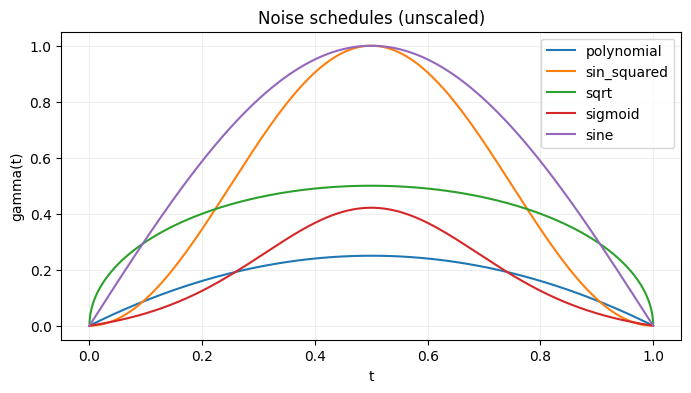

In [30]:
ts = torch.linspace(1e-4, 1 - 1e-4, 1000).unsqueeze(1)
plt.figure(figsize=(8, 4))
for schedule in ["polynomial", "sin_squared", "sqrt", "sigmoid", "sine"]:
    gamma, _ = noise_schedule(ts, schedule=schedule)
    plt.plot(ts[:, 0].numpy(), gamma[:, 0].numpy(), label=schedule)
plt.xlabel("t")
plt.ylabel("gamma(t)")
plt.title("Noise schedules (unscaled)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 3. Choose the target distribution

Use the eight-Gaussians dataset as the primary benchmark; change `TARGET` to `"spiral"` or `"boltzmann"` to repeat the complete comparison. `metropolis` returns correlated samples; the resulting training target can be biased if the chain is not adequately mixed between wells.

Metropolis acceptance at kBT=1.0: 0.296
Data shape: (20000, 2)


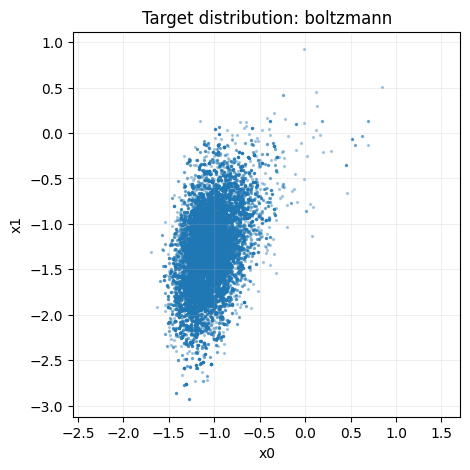

In [31]:
TARGET = "boltzmann"  # "eight_gaussians", "spiral", or "boltzmann"
N_TARGET = 20000
KBT = 1.0  # used only for the Boltzmann target

def make_target(name, n=N_TARGET, seed=SEED, kBT=KBT):
    if name == "eight_gaussians":
        return eight_gaussians(n, radius=4, std=0.5, seed=seed)
    if name == "spiral":
        return spiral(n, turns=2.0, radius=4.0, noise=0.15, seed=seed)
    if name == "boltzmann":
        data, rate = metropolis(n, kBT=kBT, step_size=0.5, burn_in=5000, seed=seed)
        print(f"Metropolis acceptance at kBT={kBT}: {rate:.3f}")
        return data
    raise ValueError(f"Unknown target: {name}")

target_data = make_target(TARGET)
print("Data shape:", target_data.shape)
plt.figure(figsize=(5, 5))
plt.scatter(target_data[:, 0], target_data[:, 1], s=2, alpha=0.3)
plt.title(f"Target distribution: {TARGET}")
plt.xlabel("x0"); plt.ylabel("x1")
plt.axis("equal"); plt.grid(alpha=0.2)
plt.show()

## 4. Train all interpolants

**Controlled comparison:** same target dataset, network architecture, batch size, learning rate, iteration count and initialization seed. The training data pairs and stochastic noise can still differ because the interpolation rules are different.

Set `N_ITERATIONS=10000` for the original full training budget. The default `2000` is a **quick exploratory run**, not the final research setting. Training seven networks can be time-consuming, especially on CPU. Results are cached as model state dictionaries and loss histories.

In [32]:
N_ITERATIONS = 2000  # switch to 10000 for the final comparison
BATCH_SIZE = 512
LR = 1e-3
HIDDEN_DIM = 256
RK4_STEPS = 100
N_GENERATED = 3000

models = {}
losses = {}

for name, interpolant in INTERPOLANTS.items():
    print(f"Training {name}...")
    torch.manual_seed(SEED)  # same initial network weights per method
    try:
        model, history = train_model(
            target_data, interpolant=interpolant,
            n_iterations=N_ITERATIONS, batch_size=BATCH_SIZE,
            lr=LR, hidden_dim=HIDDEN_DIM, device=device
        )
        if not np.isfinite(history).all():
            print(f"  WARNING: non-finite loss for {name}; excluding this model")
            continue
    except (FloatingPointError, ValueError, RuntimeError) as exc:
        print(f"  FAILED: {name}: {exc}")
        continue
    models[name] = model
    losses[name] = history
    torch.save({"state_dict": model.state_dict(), "iterations": N_ITERATIONS,
                "method": name, "target": TARGET, "kBT": KBT},
               RESULTS_DIR / f"{TARGET}_{name}_{N_ITERATIONS}.pt")
    print(f"  final batch MSE: {history[-1]:.4f}")

print("Trained models:", list(models))

Training linear...
  final batch MSE: 0.4697
Training trigonometric...
  final batch MSE: 0.7181
Training noisy_polynomial...
  final batch MSE: 0.6638
Training noisy_sin_squared...
  final batch MSE: 1.6516
Training noisy_sqrt...
  final batch MSE: 1.2470
Training noisy_sigmoid...
  final batch MSE: 0.7803
Training noisy_sine_custom...
  final batch MSE: 1.7167
Trained models: ['linear', 'trigonometric', 'noisy_polynomial', 'noisy_sin_squared', 'noisy_sqrt', 'noisy_sigmoid', 'noisy_sine_custom']


### Training loss

Batch MSE values are **not directly comparable across different interpolants**: the target velocity itself changes. We plot learning curves to inspect optimization stability, not to rank final sample quality.

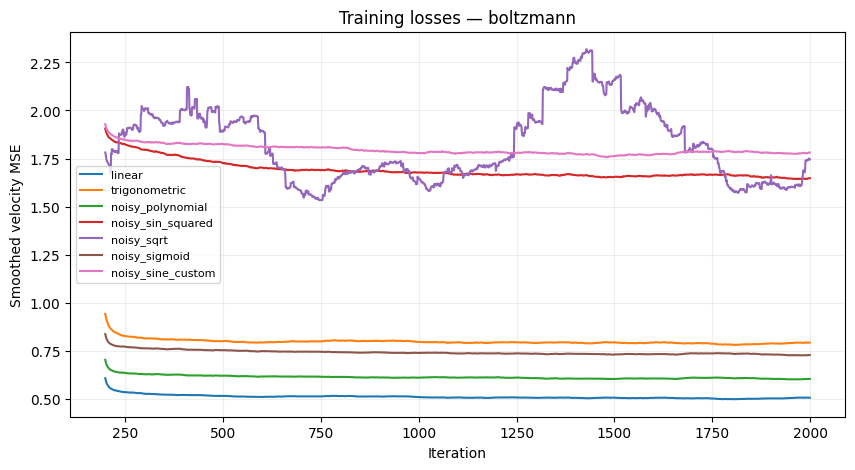

In [33]:
fig, ax = plt.subplots(figsize=(10, 5))
for name, history in losses.items():
    window = min(200, max(1, len(history) // 10))
    smoothed = np.convolve(history, np.ones(window) / window, mode="valid")
    ax.plot(np.arange(window - 1, len(history)), smoothed, label=name)
ax.set(xlabel="Iteration", ylabel="Smoothed velocity MSE",
       title=f"Training losses — {TARGET}")
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
plt.show()

## 5. Compare generated and target distributions

All methods start from the **same** Gaussian samples for the RK4 integration. Target points and generated points are plotted with the same count. The distributions may appear similar visually even when rare modes or tails differ.

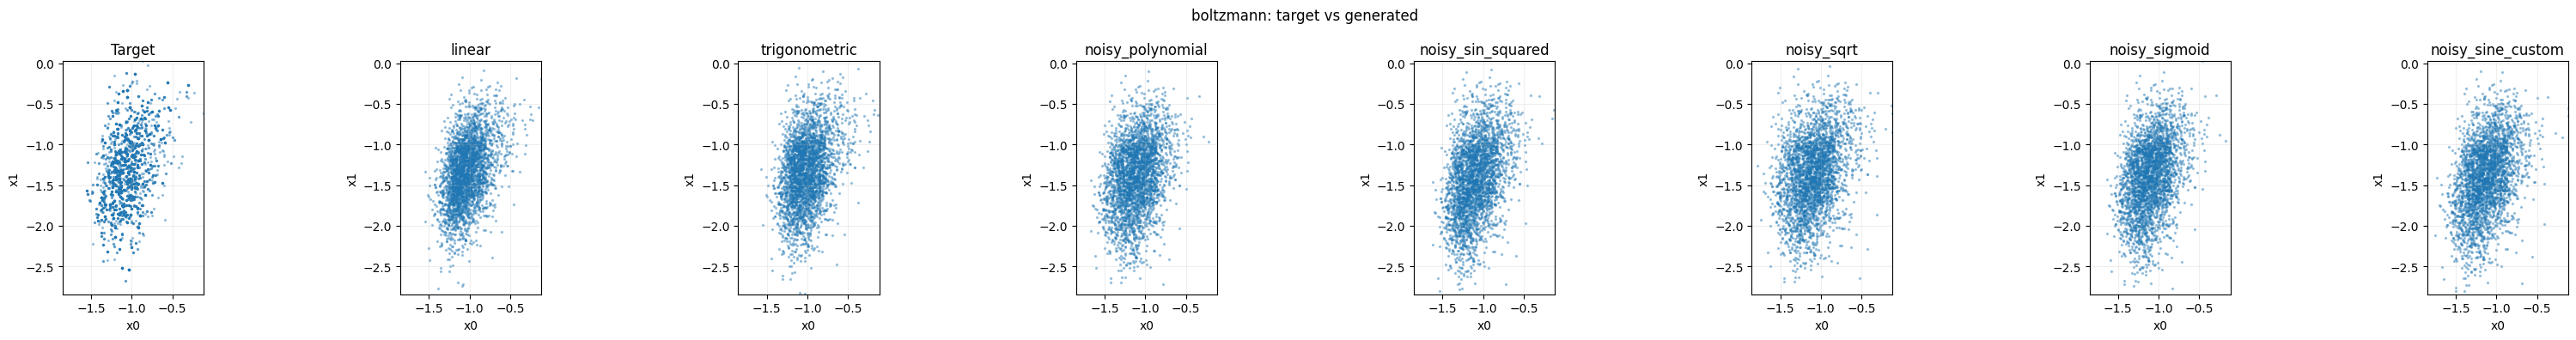

In [34]:
initial_x0 = np.random.default_rng(SEED + 1).standard_normal((N_GENERATED, 2)).astype(np.float32)
rk4_generated = {
    name: generate_samples(model, n_steps=RK4_STEPS, x0=initial_x0)
    for name, model in models.items()
}

def plot_sample_comparison(reference, generated_dict, title=""):
    count = len(generated_dict) + 1
    fig, axes = plt.subplots(1, count, figsize=(4 * count, 4), squeeze=False)
    axes = axes[0]
    datasets = [("Target", reference[:N_GENERATED])] + list(generated_dict.items())
    all_points = np.concatenate([data for _, data in datasets])
    lo, hi = np.percentile(all_points, [0.5, 99.5], axis=0)
    margin = np.maximum((hi - lo) * 0.1, 0.3)
    for ax, (name, pts) in zip(axes, datasets):
        ax.scatter(pts[:, 0], pts[:, 1], s=2, alpha=0.35)
        ax.set(title=name, xlabel="x0", ylabel="x1")
        ax.set_xlim(lo[0] - margin[0], hi[0] + margin[0])
        ax.set_ylim(lo[1] - margin[1], hi[1] + margin[1])
        ax.set_aspect("equal")
        ax.grid(alpha=0.2)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_sample_comparison(target_data, rk4_generated, f"{TARGET}: target vs generated")

## 6. Learned velocity fields at $t=0,0.5,1$

The arrows represent the learned transport velocities $v_\theta(x,t)$, **not** the physical force $-\nabla V(x)$ in the Boltzmann example. We use a common arrow scale across panels to make their magnitudes comparable. Far outside the training mass, the learned field may be unreliable.

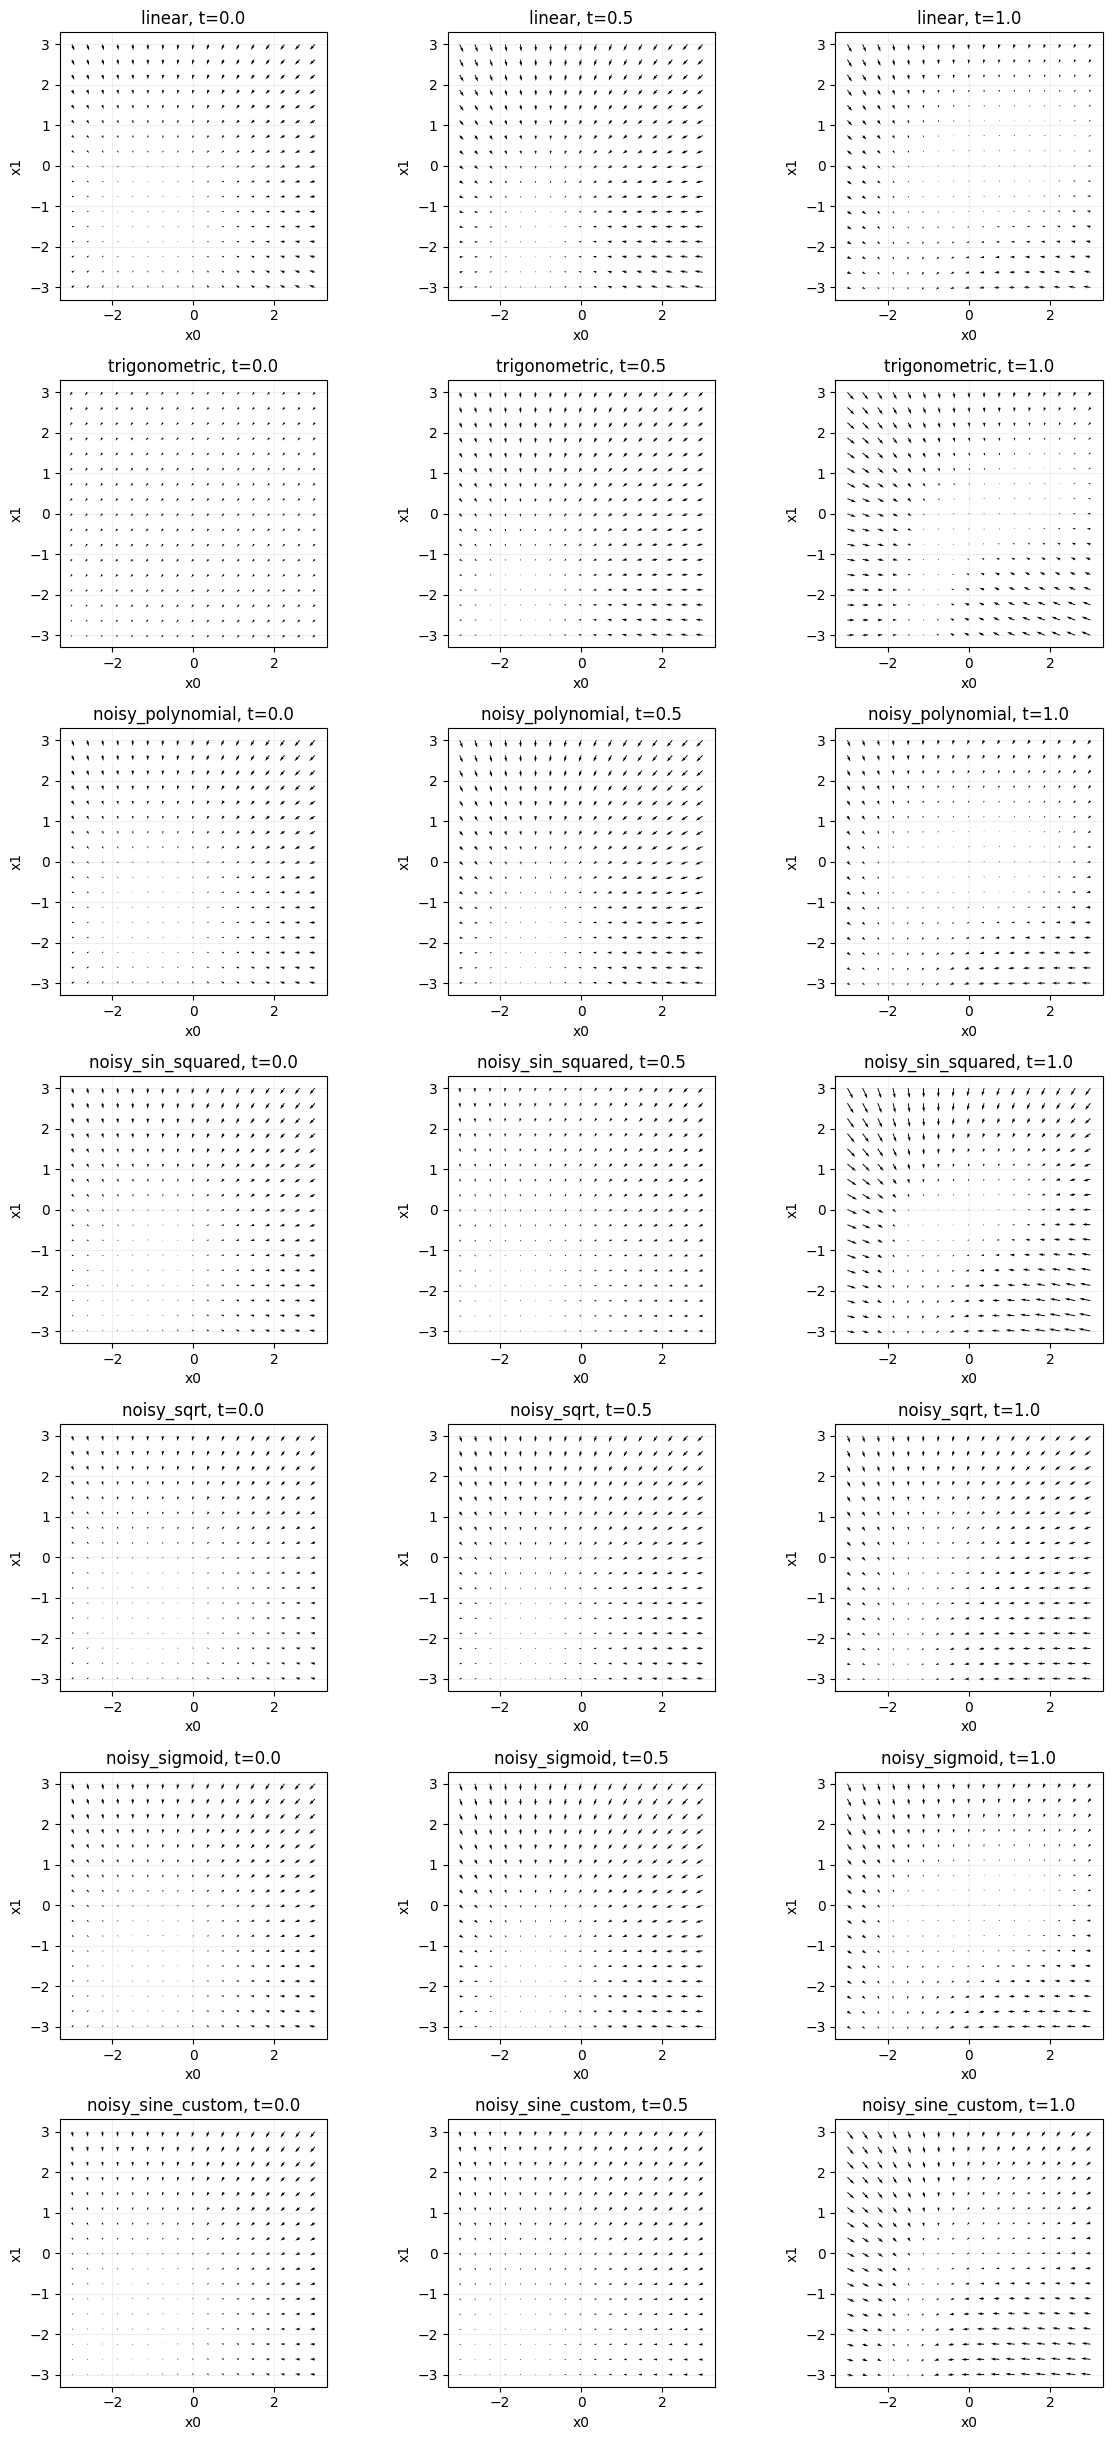

In [40]:
TIMES = [0.0, 0.5, 1.0]
grid_axis = np.linspace(-4.5, 4.5, 17) if TARGET != "boltzmann" else np.linspace(-3, 3, 17)
GX, GY = np.meshgrid(grid_axis, grid_axis)
xy = np.column_stack([GX.ravel(), GY.ravel()]).astype(np.float32)
grid_torch = torch.as_tensor(xy, dtype=torch.float32, device=device)

fields = {}
for name, model in models.items():
    fields[name] = []
    for tt in TIMES:
        t_batch = torch.full((len(grid_torch), 1), tt, device=device)
        with torch.no_grad():
            v = model(grid_torch, t_batch).cpu().numpy()
        fields[name].append(v)

if fields:
    max_speed = max(np.linalg.norm(v, axis=1).max() for vs in fields.values() for v in vs)
    
    grid_step = grid_axis[1] - grid_axis[0]
    common_scale = max(max_speed, 1e-5) / (0.8 * grid_step)

    fig, axes = plt.subplots(len(fields), len(TIMES),
                             figsize=(12, 3.5 * len(fields)), squeeze=False)
    for i, (name, series) in enumerate(fields.items()):
        for j, (tt, v) in enumerate(zip(TIMES, series)):
            axes[i, j].quiver(GX, GY, v[:, 0].reshape(GX.shape), v[:, 1].reshape(GY.shape),
                              angles="xy", scale_units="xy", scale=common_scale)
            axes[i, j].set(title=f"{name}, t={tt}", xlabel="x0", ylabel="x1")
            axes[i, j].set_aspect("equal")
            axes[i, j].grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

## 7. Effect of RK4 steps

A smaller number of ODE integration steps makes sampling faster but introduces discretization error. Compare models using the **same starting points**, at fixed trained weights.

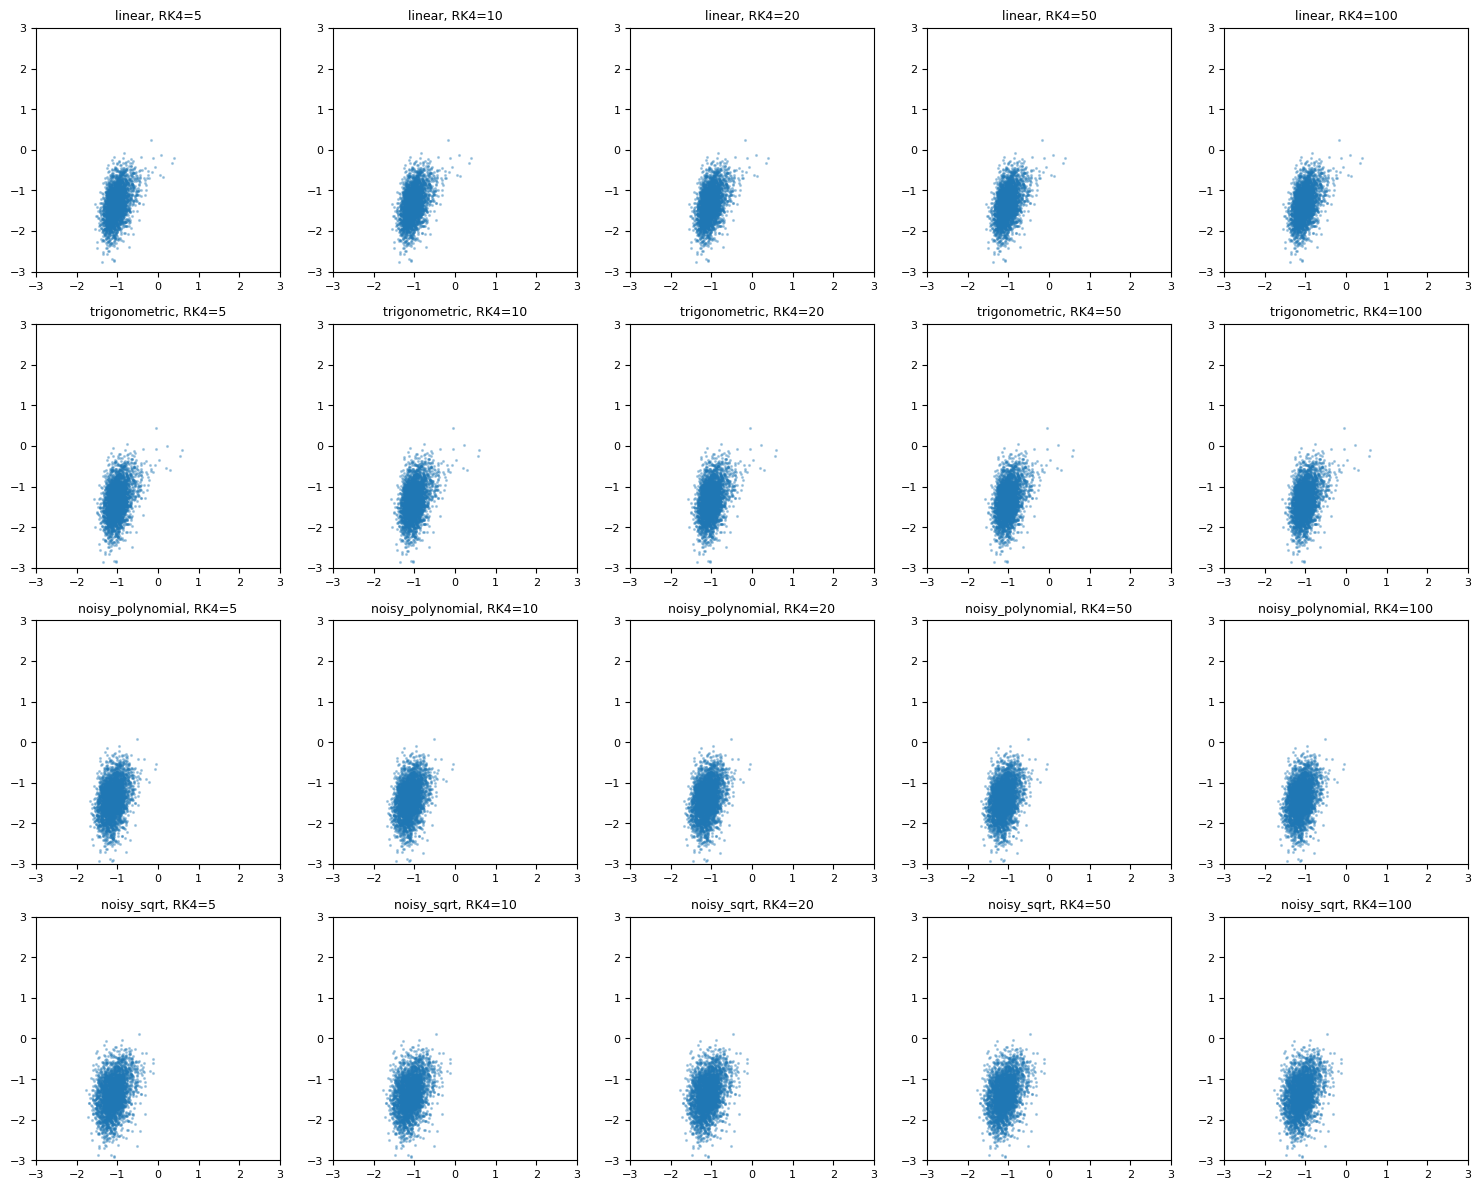

In [36]:
STEP_COUNTS = [5, 10, 20, 50, 100]
# Reduce visualization clutter: use a selected subset of the methods, or list(models) for all.
METHODS_FOR_RK4 = [n for n in ["linear", "trigonometric", "noisy_polynomial", "noisy_sqrt"] if n in models]

fig, axes = plt.subplots(len(METHODS_FOR_RK4), len(STEP_COUNTS),
                         figsize=(3 * len(STEP_COUNTS), 3 * max(1, len(METHODS_FOR_RK4))), squeeze=False)
for i, name in enumerate(METHODS_FOR_RK4):
    for j, steps in enumerate(STEP_COUNTS):
        pts = generate_samples(models[name], n_steps=steps, x0=initial_x0)
        ax = axes[i, j]
        ax.scatter(pts[:, 0], pts[:, 1], s=1.5, alpha=0.3)
        ax.set_title(f"{name}, RK4={steps}", fontsize=9)
        ax.set_aspect("equal")
        ax.set_xlim(GX.min(), GX.max()); ax.set_ylim(GY.min(), GY.max())
        ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

## 8. A few trajectories

For each method, integrate the *same* few starting samples, recording the position after every RK4 step. The resulting curves are ODE trajectories, and should not be confused with the sampled interpolant paths used during training.

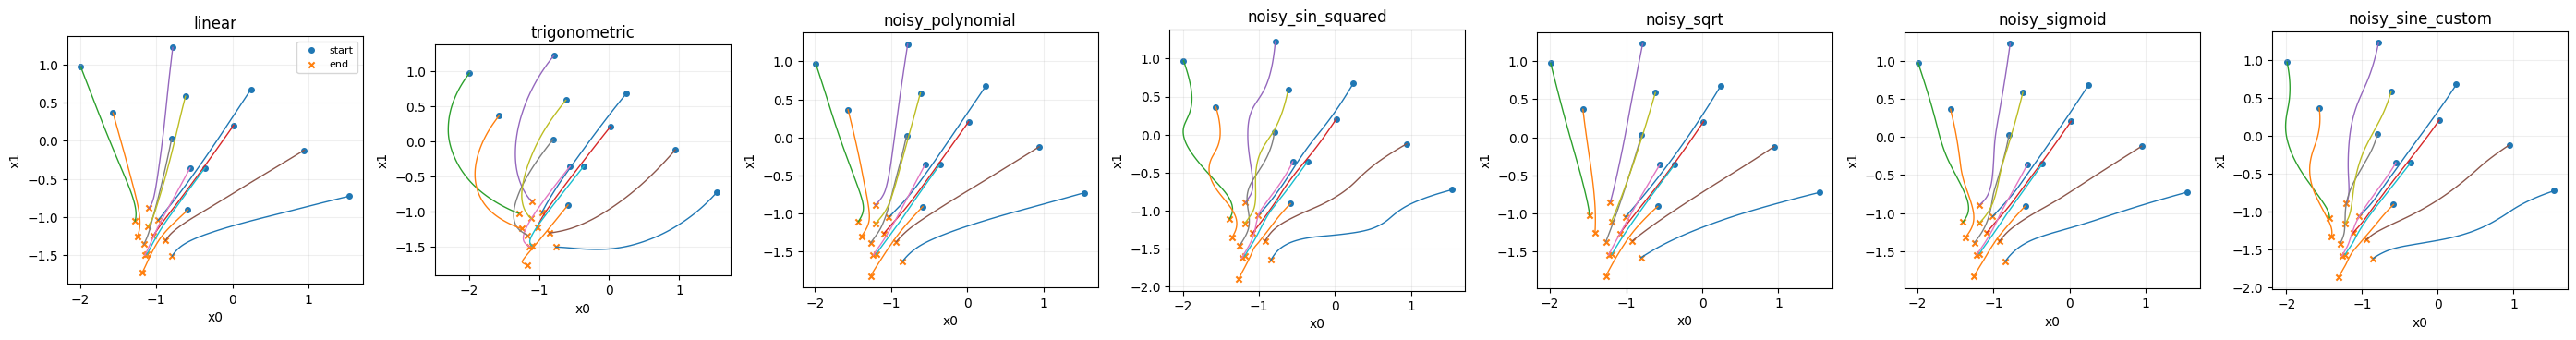

In [37]:
@torch.no_grad()
def generate_trajectories(model, x0, n_steps=100):
    model.eval()
    x = torch.as_tensor(x0, dtype=torch.float32, device=next(model.parameters()).device).clone()
    dt = 1.0 / n_steps
    path = [x.cpu().numpy().copy()]
    for i in range(n_steps):
        t = torch.full((len(x), 1), i * dt, device=x.device)
        k1 = model(x, t)
        k2 = model(x + 0.5 * dt * k1, t + 0.5 * dt)
        k3 = model(x + 0.5 * dt * k2, t + 0.5 * dt)
        k4 = model(x + dt * k3, t + dt)
        x += dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        path.append(x.cpu().numpy().copy())
    return np.stack(path)

n_trajectories = 12
start = initial_x0[:n_trajectories]
fig, axes = plt.subplots(1, len(models), figsize=(4 * max(1, len(models)), 4), squeeze=False)
for ax, (name, model) in zip(axes[0], models.items()):
    path = generate_trajectories(model, start, n_steps=100)
    for j in range(n_trajectories):
        ax.plot(path[:, j, 0], path[:, j, 1], linewidth=1)
    ax.scatter(path[0, :, 0], path[0, :, 1], s=16, marker="o", label="start")
    ax.scatter(path[-1, :, 0], path[-1, :, 1], s=20, marker="x", label="end")
    ax.set(title=name, xlabel="x0", ylabel="x1")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
if len(models): axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 9. Simple numerical comparison

Compare sample means, standard deviations and, for Boltzmann, mean potential energy. These are **partial diagnostics**, not a complete statistical distance. For multimodal targets, also inspect mode coverage and relative mode weights.

In [38]:
def sample_stats(x):
    return np.mean(x, axis=0), np.std(x, axis=0)

print(f"{'Method':23s} {'mean x0':>9s} {'mean x1':>9s} {'std x0':>9s} {'std x1':>9s}")
for name, pts in [("target", target_data[:N_GENERATED])] + list(rk4_generated.items()):
    mu, sd = sample_stats(pts)
    print(f"{name:23s} {mu[0]:9.3f} {mu[1]:9.3f} {sd[0]:9.3f} {sd[1]:9.3f}")

if TARGET == "boltzmann":
    print("\nMean potential energies:")
    for name, pts in [("target", target_data[:N_GENERATED])] + list(rk4_generated.items()):
        print(f"{name:23s} {potential(pts).mean():9.3f}")

Method                    mean x0   mean x1    std x0    std x1
target                     -1.057    -1.296     0.199     0.453
linear                     -1.028    -1.328     0.195     0.400
trigonometric              -1.006    -1.324     0.205     0.430
noisy_polynomial           -1.111    -1.389     0.205     0.435
noisy_sin_squared          -1.091    -1.425     0.205     0.467
noisy_sqrt                 -1.097    -1.367     0.231     0.446
noisy_sigmoid              -1.099    -1.395     0.203     0.444
noisy_sine_custom          -1.129    -1.407     0.216     0.450

Mean potential energies:
target                     -2.295
linear                     -2.440
trigonometric              -2.276
noisy_polynomial           -2.162
noisy_sin_squared          -2.167
noisy_sqrt                 -1.978
noisy_sigmoid              -2.213
noisy_sine_custom          -2.062
